In [1]:
!pip install transformers gradio pillow -q

from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers.utils import logging
import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity_error()

print('Loading BLIP model...')
processor  = BlipProcessor.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
blip_model = BlipForConditionalGeneration.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
print('BLIP ready!')


Loading BLIP model...


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

BLIP ready!


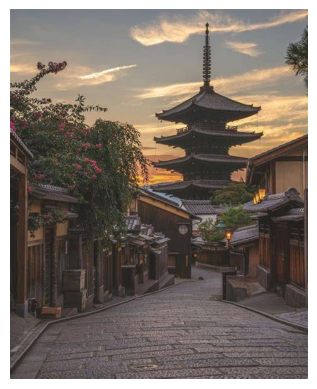

Image size: (474, 589)


In [3]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Read the image as bytes
with open('/content/img genration 1.jpg', 'rb') as file:
    image_bytes = file.read()

# Load the image using BytesIO
image = Image.open(BytesIO(image_bytes)).convert("RGB")

# Display the image
plt.imshow(image)
plt.axis("off")
plt.show()

# Print image size
print("Image size:", image.size)

In [4]:
def get_caption(image):
    # Step A: prepare the image for BLIP
    inputs = processor(image.convert('RGB'), return_tensors='pt')

    # Step B: generate the caption
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)

    # Step C: convert numbers back to text
    caption = processor.decode(output[0], skip_special_tokens=True)
    return caption

print('get_caption() function ready!')


get_caption() function ready!


In [5]:
import torch

caption = get_caption(image)

print("BLIP says:")
print(f'  "{caption}"')
print()
print(f"Word count: {len(caption.split())} words")

BLIP says:
  "a street in kyoto, japan"

Word count: 5 words


In [6]:
def get_caption_with_prompt(image, prompt):
    # Same as before — but we add a starting text
    inputs = processor(image.convert('RGB'),
                       text   = prompt,
                       return_tensors = 'pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)
    return processor.decode(output[0], skip_special_tokens=True)


# Same image — different starting prompts
prompts = [
    'a photo of',
    'this image shows',
    'there are',
]

print('Same image — different prompts:')
print()
for prompt in prompts:
    result = get_caption_with_prompt(image, prompt)
    print(f'Prompt  : "{prompt}"')
    print(f'Caption : "{result}"')
    print()


Same image — different prompts:

Prompt  : "a photo of"
Caption : "a photo of a street in kyoto, japan"

Prompt  : "this image shows"
Caption : "this image shows a street in kyoto, japan"

Prompt  : "there are"
Caption : "there are many places in japan that you can visit, like the old town of kyoto"



In [7]:
import pandas as pd

token_lengths = [20, 40, 60, 80]
results = []

for max_t in token_lengths:
    inputs = processor(image.convert('RGB'), return_tensors='pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=max_t)
    cap   = processor.decode(output[0], skip_special_tokens=True)
    words = len(cap.split())
    results.append({'max_tokens': max_t, 'words': words, 'caption': cap})
    print(f'max_tokens={max_t:3d} → {words} words: {cap}')

print()
print('More tokens = longer caption')
print('But after a point the caption does not grow much more')


max_tokens= 20 → 5 words: a street in kyoto, japan
max_tokens= 40 → 5 words: a street in kyoto, japan
max_tokens= 60 → 5 words: a street in kyoto, japan
max_tokens= 80 → 5 words: a street in kyoto, japan

More tokens = longer caption
But after a point the caption does not grow much more


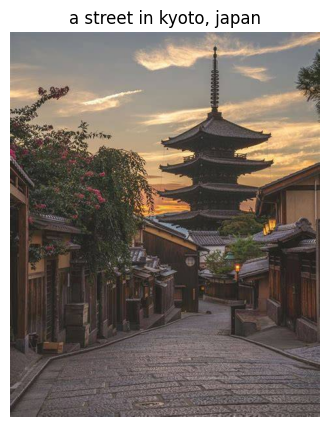

Image: /content/img genration 1.jpg
Caption: a street in kyoto, japan
--------------------------------------------------


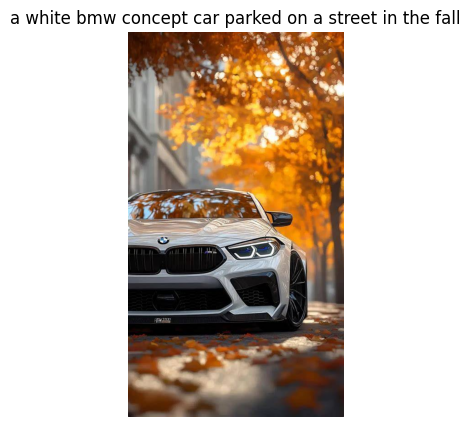

Image: /content/img genration 2.jpg
Caption: a white bmw concept car parked on a street in the fall
--------------------------------------------------


In [8]:
from PIL import Image
import matplotlib.pyplot as plt

# Image paths in Google Colab
image_paths = [
    "/content/img genration 1.jpg",
    "/content/img genration 2.jpg"
]

for image_path in image_paths:
    try:
        # Open the local image
        img = Image.open(image_path).convert("RGB")

        # Generate caption using BLIP
        caption = get_caption(img)

        # Display image and caption
        plt.figure(figsize=(8, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(caption, wrap=True)
        plt.show()

        print("Image:", image_path)
        print("Caption:", caption)
        print("-" * 50)

    except Exception as e:
        print("Error:", e)

In [12]:

import gradio as gr
from PIL import Image
import os

# Generate captions for all uploaded images
def caption_app(files, prompt):
    if not files:
        return [], "⚠️ Please upload at least one image."

    results = []
    errors = []

    for file in files:
        try:
            path = file if isinstance(file, str) else file.name
            img = Image.open(path).convert("RGB")

            if prompt and prompt.strip():
                caption = get_caption_with_prompt(img, prompt.strip())
            else:
                caption = get_caption(img)

            results.append((img, caption))

        except Exception as e:
            errors.append(f"{os.path.basename(str(file))}: {e}")

    status = f"✅ Generated captions for {len(results)} image(s)."
    if errors:
        status += "\n\n⚠️ Some images could not be processed:\n" + "\n".join(errors)

    return results, status


# Custom CSS: light background, no grey heading blocks
css = """
body,
.gradio-container {
    background: #f2f7ff !important;
    font-family: Arial, Helvetica, sans-serif !important;
}

.gradio-container {
    max-width: 1500px !important;
    margin: auto !important;
    padding: 24px 32px !important;
}

/* Header */
#hero {
    background: linear-gradient(115deg, #ffffff, #eaf3ff) !important;
    border: 1px solid #d8e7ff !important;
    border-radius: 20px !important;
    padding: 26px 32px !important;
    margin-bottom: 24px !important;
}

#hero h1 {
    color: #102b69 !important;
    background: transparent !important;
    font-size: 38px !important;
    font-weight: 800 !important;
    margin: 0 0 8px 0 !important;
}

#hero p {
    color: #49658e !important;
    background: transparent !important;
    font-size: 17px !important;
    margin: 0 !important;
}

/* Main panels */
.panel {
    background: #ffffff !important;
    border: 1px solid #d5e5ff !important;
    border-radius: 18px !important;
    padding: 24px !important;
    box-shadow: 0 5px 20px rgba(30, 83, 160, 0.06) !important;
}

/* Remove grey backgrounds from Markdown containers */
.gradio-container .prose,
.gradio-container .prose *,
.gradio-container .markdown,
.gradio-container .markdown *,
.gradio-container [data-testid="markdown"],
.gradio-container [data-testid="markdown"] *,
.gradio-container .form,
.gradio-container .label-wrap {
    background-color: transparent !important;
}

/* Ensure all headings have a clean background */
.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container h4,
.gradio-container p,
.gradio-container strong {
    background: transparent !important;
    box-shadow: none !important;
}

/* Section headings */
.section-title {
    color: #102b69 !important;
    background: transparent !important;
    font-size: 21px !important;
    font-weight: 750 !important;
    margin-bottom: 8px !important;
    line-height: 1.5 !important;
}

/* Section descriptions */
.section-description {
    color: #536d94 !important;
    background: transparent !important;
    font-size: 14px !important;
    line-height: 1.7 !important;
    margin-bottom: 14px !important;
}

/* Upload area */
#upload-box {
    border: 2px dashed #bfd5ff !important;
    border-radius: 14px !important;
    background: #f8fbff !important;
    padding: 14px !important;
}

/* Preserve upload widget's interactive controls */
#upload-box button,
#upload-box input {
    background-color: inherit;
}

/* Prompt input */
.gradio-container textarea,
.gradio-container input {
    border-color: #d5e5ff !important;
    border-radius: 10px !important;
}

/* Generate button */
#generate {
    background: linear-gradient(90deg, #2865f5, #397fff) !important;
    color: #ffffff !important;
    border: none !important;
    border-radius: 12px !important;
    font-size: 17px !important;
    font-weight: bold !important;
    min-height: 54px !important;
}

#generate:hover {
    filter: brightness(1.04);
}

/* Results panel */
#results-panel {
    background: #ffffff !important;
    border: 1px solid #d5e5ff !important;
    border-radius: 18px !important;
    padding: 24px !important;
    box-shadow: 0 5px 20px rgba(30, 83, 160, 0.06) !important;
}

#results-panel h2,
#results-panel h3 {
    color: #102b69 !important;
    background: transparent !important;
    font-size: 23px !important;
}

/* Gallery */
#results-gallery {
    border-radius: 14px !important;
    border: 1px solid #e0ebff !important;
    background: #f9fbff !important;
}

#results-gallery figure {
    border-radius: 12px !important;
    border: 1px solid #e0ebff !important;
    overflow: hidden !important;
}

/* Status */
#status {
    color: #315d9d !important;
    background: transparent !important;
    font-size: 14px !important;
    margin-top: 8px !important;
}

/* Labels */
.gradio-container label {
    color: #17366f !important;
    font-weight: 600 !important;
}

/* Footer */
#footer {
    text-align: center !important;
    color: #3e659b !important;
    background: transparent !important;
    padding: 22px !important;
    font-size: 14px !important;
}

/* Responsive layout */
@media (max-width: 768px) {
    .gradio-container {
        padding: 12px !important;
    }

    #hero {
        padding: 20px !important;
    }

    #hero h1 {
        font-size: 27px !important;
    }

    .panel,
    #results-panel {
        padding: 16px !important;
    }
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="sky",
        neutral_hue="slate"
    ),
    css=css,
    title="Image Caption Generation"
) as app:

    # Header
    with gr.Row(elem_id="hero"):
        with gr.Column():
            gr.Markdown(
                "# 🖼️ Image Caption Generation\n"
                "Upload any image and let AI describe it!"
            )
            gr.Markdown("✨ Powered by BLIP (Salesforce)")

    # Main two-column layout
    with gr.Row(equal_height=False):

        # LEFT: Upload and prompt
        with gr.Column(scale=4, min_width=320):
            with gr.Group(elem_classes=["panel"]):

                gr.Markdown(
                    '<div class="section-title">📤 1. Upload Images</div>'
                    '<div class="section-description">'
                    'Choose images from your computer (JPG, PNG, WEBP).'
                    '</div>'
                )

                image_input = gr.File(
                    label="Click to upload or drag and drop",
                    file_count="multiple",
                    file_types=["image"],
                    type="filepath",
                    elem_id="upload-box"
                )

                gr.Markdown(
                    '<div class="section-title">💡 2. Optional Prompt</div>'
                    '<div class="section-description">'
                    'Guide the caption with a starting phrase, or leave it empty.'
                    '</div>'
                )

                prompt_input = gr.Textbox(
                    label="Starting prompt",
                    placeholder='Example: "a photo of" — or leave empty',
                    lines=2,
                    max_lines=2
                )

                generate_btn = gr.Button(
                    "✨ Generate Captions",
                    variant="primary",
                    elem_id="generate"
                )

                status_output = gr.Markdown(
                    "Upload images to get started.",
                    elem_id="status"
                )

        # RIGHT: Results
        with gr.Column(scale=8, min_width=400):
            with gr.Group(elem_id="results-panel"):

                gr.Markdown(
                    "## 🪄 Image Preview & AI Captions"
                )

                gr.Markdown(
                    "Each uploaded image will appear with its generated caption."
                )

                results_output = gr.Gallery(
                    label="Generated Results",
                    columns=[2],
                    rows=[2],
                    height=560,
                    object_fit="contain",
                    allow_preview=True,
                    show_label=False,
                    elem_id="results-gallery"
                )

    # Footer
    gr.Markdown(
        "💙 **Turn your images into words — with the power of AI!**",
        elem_id="footer"
    )

    generate_btn.click(
        fn=caption_app,
        inputs=[image_input, prompt_input],
        outputs=[results_output, status_output]
    )

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a1839f30305aa696d0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
